# Through the middle: a barrier method for the same LP

`simplex_by_hand.ipynb` walked the edges of the feasible region from corner to corner. A barrier
(interior-point) method never touches an edge until the very end. It replaces the hard constraints
$x \ge 0$ with a penalty that grows without limit near them, solves that smooth problem, then
weakens the penalty a little and solves again. The solutions trace a curve through the interior,
the **central path**, that ends at the optimal corner.

Same LP: maximise $40x_1 + 50x_2$ with $x_1 + 2x_2 \le 40$ and $4x_1 + 3x_2 \le 120$.

## Setup: where the package lives

This notebook builds the method by hand and then checks it against `orteach`, the package in
`src/`. Run from a clone of the repository, `../../src` is right there. On Colab there is no clone
until this cell makes one, and no `gurobipy` until it installs it. Nothing here needs a secret.

In [1]:
import os, subprocess, sys

REPO_URL = "https://github.com/sear-labs/teaching-code"
REF = "v1.0.0"                               # the release this notebook ships in: Colab clones THIS

try:
    import google.colab                      # noqa: F401 - succeeds only on Colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if ON_COLAB:
    if not os.path.isdir("/content/teaching-code"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REF, REPO_URL, "/content/teaching-code"], check=True)
    os.chdir("/content/teaching-code/notebooks/02_simplex_and_bases")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "gurobipy>=11,<14"], check=True)

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "src")))
try:
    import orteach                            # noqa: F401
except ImportError:
    raise SystemExit("orteach not found: run this notebook from its own folder inside the repository, "
                     "so that ../../src exists.")
root = os.path.abspath(os.path.join("..", ".."))
print("package:", os.path.relpath(os.path.dirname(orteach.__file__), root))

package: src\orteach


## Licence setup

Only the cross-check at the end uses a solver. Nothing here needs a key: `pip install gurobipy`
ships a size-limited licence and this model is tiny. The environment starts silent, so no licence
number lands in an output cell.

In [2]:
import gurobipy as gp
from gurobipy import GRB

env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)        # start silent: the licence banner, and its licence number, stay out of the outputs
try:
    from google.colab import userdata
    try:
        env.setParam("WLSACCESSID", userdata.get("GRB_WLSACCESSID"))
        env.setParam("WLSSECRET",   userdata.get("GRB_WLSSECRET"))
        env.setParam("LICENSEID",   int(userdata.get("GRB_LICENSEID")))
        licence = "Colab Secrets (WLS)"
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        licence = "the size-limited licence pip ships"     # no key needed; see the note above
except ImportError:
    licence = "local gurobi.lic"
env.start()
print("licence:", licence)

licence: local gurobi.lic


## Standard form, and a point strictly inside

The same four columns as the tableau notebook: $x_1, x_2$ and one slack per row, with $Ax = b$.
A barrier method has to start strictly inside, every variable positive. Take $x_1 = x_2 = 1$; the
slacks follow from the equations.

In [3]:
import numpy as np
from orteach import tolerance
from orteach.duality import load_lp

lp = load_lp("lp_simplex_40_50.csv")
names = ["x1", "x2", "s1", "s2"]
A = np.array([[lp.A["c1", "x1"], lp.A["c1", "x2"], 1.0, 0.0],
              [lp.A["c2", "x1"], lp.A["c2", "x2"], 0.0, 1.0]])
b = np.array([lp.b["c1"], lp.b["c2"]])
c = np.array([lp.c["x1"], lp.c["x2"], 0.0, 0.0])

X0 = {"x1": 1.0, "x2": 1.0}
x = np.array([X0["x1"], X0["x2"], b[0] - A[0, :2] @ [1.0, 1.0], b[1] - A[1, :2] @ [1.0, 1.0]])
print("start", dict(zip(names, x.tolist())), "  all positive:", bool((x > 0).all()), "  A x - b =", A @ x - b)

start {'x1': 1.0, 'x2': 1.0, 's1': 37.0, 's2': 113.0}   all positive: True   A x - b = [0. 0.]


## The barrier problem

Maximising $c^\top x$ is minimising $-c^\top x$. Add $-\sum_i \log x_i$, which is small in the
middle and rises without bound as any $x_i$ approaches zero, and weigh the original objective by a
number $t$:

$$\min_x\; f_t(x) = -t\,c^\top x - \sum_i \log x_i \quad\text{subject to}\quad Ax = b.$$

Small $t$: the log term dominates and the minimiser sits deep inside. Large $t$: the objective
dominates and the minimiser approaches the optimal corner. `T0` is where the path starts and `MU`
how much $t$ grows each time; both are knobs.

In [4]:
T0 = 0.001
MU = 2.0
t = T0

f_now = -t * c @ x - np.log(x).sum()
print(f"t = {t}   f_t(start) = {f_now:.4f}")

t = 0.001   f_t(start) = -8.4283


## One Newton step

Newton's method for a smooth problem with equality constraints: build the gradient $g$ and the
Hessian $H$ of $f_t$, then solve one linear system for a step $\Delta x$ that keeps $A\Delta x = 0$
(so the equations stay satisfied):

$$\begin{bmatrix} H & A^\top \\ A & 0 \end{bmatrix}\begin{bmatrix}\Delta x\\ w\end{bmatrix} =
\begin{bmatrix} -g \\ 0\end{bmatrix}, \qquad g = -t\,c - 1/x, \qquad H = \mathrm{diag}(1/x^2).$$

The Newton decrement $\lambda^2 = \Delta x^\top H \Delta x$ says how far from the minimiser this
point is; half of it estimates how much $f_t$ can still fall. Predict before running: at the
start, far from the centre, will the decrement be large or small, and what should $A\Delta x$ be?

In [5]:
g = -t * c - 1.0 / x
H = np.diag(1.0 / x ** 2)
K = np.block([[H, A.T], [A, np.zeros((2, 2))]])
dx = np.linalg.solve(K, np.concatenate([-g, np.zeros(2)]))[:4]
lam2 = float(dx @ H @ dx)
print("step", dx.round(4), "  A @ step =", (A @ dx).round(12), "  decrement^2 / 2 =", round(lam2 / 2, 4))

step [ 0.9733  0.9636 -2.9005 -6.784 ]   A @ step = [0. 0.]   decrement^2 / 2 = 0.9428


A full Newton step can overshoot past zero, where the logarithm does not exist. So halve the step
until the new point is strictly inside and $f_t$ has dropped by at least a quarter of what the
decrement predicts; that fraction, `ARMIJO`, is a knob of the line search. Predict before running:
will the first, full step survive?

In [6]:
ARMIJO = 0.25
step = 1.0
f_x = -t * c @ x - np.log(x).sum()
while (x + step * dx <= 0).any() or (-t * c @ (x + step * dx) - np.log(x + step * dx).sum()) > f_x - ARMIJO * step * lam2:
    step *= 0.5
print(f"ARMIJO {ARMIJO}: step length accepted {step}")

ARMIJO 0.25: step length accepted 1.0


## Centering, then the path

Repeat that step until the decrement is negligible: that point is on the central path for this $t$.
Then multiply $t$ by `MU` and center again. The duality gap of a central point is at most (number of
variables) / $t$, so stop once that bound is below `CROSS_METHOD_RTOL`. The two loops repeat the same
lines; nothing is decided inside them that was not decided above.

In [7]:
hand_path = [x.copy()]
newton_steps = 0
while len(x) / t > tolerance.CROSS_METHOD_RTOL:
    for _ in range(50):
        g = -t * c - 1.0 / x
        H = np.diag(1.0 / x ** 2)
        K = np.block([[H, A.T], [A, np.zeros((2, 2))]])
        dx = np.linalg.solve(K, np.concatenate([-g, np.zeros(2)]))[:4]
        lam2 = float(dx @ H @ dx)
        if lam2 / 2 < tolerance.LINALG_ATOL:
            break
        step = 1.0
        f_x = -t * c @ x - np.log(x).sum()
        while (x + step * dx <= 0).any() or (-t * c @ (x + step * dx) - np.log(x + step * dx).sum()) > f_x - ARMIJO * step * lam2:
            step *= 0.5
        x = x + step * dx
        newton_steps += 1
    hand_path.append(x.copy())
    t *= MU

final = hand_path[-1]
print(f"{len(hand_path) - 1} centerings, {newton_steps} Newton steps, final t = {t / MU:.3g}")
print("first centered point", dict(zip(names, hand_path[1].round(3).tolist())))
print("last point          ", dict(zip(names, final.round(6).tolist())), f"  objective {c @ final:.6f}")

32 centerings, 65 Newton steps, final t = 2.15e+06
first centered point {'x1': 10.299, 'x2': 7.347, 's1': 15.008, 's2': 56.765}
last point           {'x1': 24.0, 'x2': 8.0, 's1': 0.0, 's2': 0.0}   objective 1359.999999


## The picture

The feasible region, the simplex's corners, and the barrier's iterates. Predict the shape of the
path before you look: straight at the optimum, or curving?

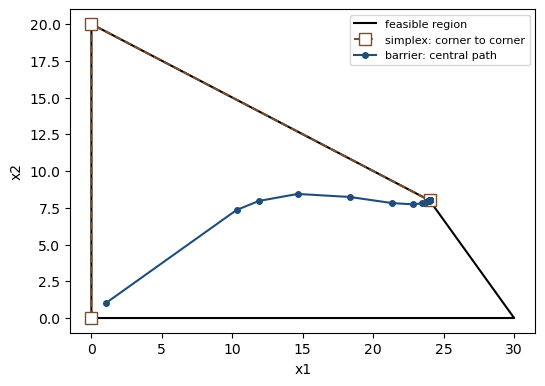

Figure: inside the four-sided region, the simplex goes from (0, 0) up to (0, 20) and across to (24, 8); the barrier starts at (1, 1), jumps to (10.3, 7.3) near the middle, and curves in to (24, 8) without touching an edge until the end.


In [8]:
import matplotlib.pyplot as plt

region = np.array([[0, 0], [0, 20], [24, 8], [30, 0], [0, 0]])          # the four feasible corners
path_xy = np.array([[p[0], p[1]] for p in hand_path])
plt.figure(figsize=(6, 4.2))
plt.plot(region[:, 0], region[:, 1], "k-", lw=1.5, label="feasible region")
plt.plot([0, 0, 24], [0, 20, 8], "s--", color="#7A4E2D", ms=8, mfc="white", label="simplex: corner to corner")
plt.plot(path_xy[:, 0], path_xy[:, 1], "o-", color="#1F4E79", ms=4, label="barrier: central path")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend(loc="upper right", fontsize=8)
plt.show()
print(f"Figure: inside the four-sided region, the simplex goes from (0, 0) up to (0, 20) and across to "
      f"(24, 8); the barrier starts at (1, 1), jumps to ({path_xy[1, 0]:.1f}, {path_xy[1, 1]:.1f}) near the "
      f"middle, and curves in to (24, 8) without touching an edge until the end.")

## A solver's barrier, for comparison

Gurobi's barrier (`Method=2`) normally finishes with a *crossover* to the exact corner. Turn
crossover off and it reports where its own interior path stopped. Predict: how close to the
corner will that be?

In [9]:
m = gp.Model("barrier check", env=env)
m.Params.Method = 2
m.Params.Crossover = 0
xg = m.addVars(lp.variables, name="x")
m.addConstrs((lp.row_expr(r, xg) <= lp.b[r] for r in lp.rows), name="row")
m.setObjective(gp.quicksum(lp.c[j] * xg[j] for j in lp.variables), GRB.MAXIMIZE)
m.optimize()
gurobi_z = m.ObjVal
print(f"Gurobi barrier, no crossover: x1 {xg['x1'].X:.6f}  x2 {xg['x2'].X:.6f}  z {gurobi_z:.6f}"
      f"   iterations {m.BarIterCount}")

Gurobi barrier, no crossover: x1 24.000000  x2 8.000000  z 1360.000000   iterations 5


---

# Now the streamlined version

The same method, once, in `orteach.simplex.barrier_path` (with `T0` and `MU` passed in, so the check
covers them), and the simplex's last corner from `tableau_path` to compare the ends.

In [10]:
from orteach import simplex as sx
from orteach.tolerance import AGREEMENT_RTOL, CROSS_METHOD_RTOL, rel_diff

pkg_path = sx.barrier_path(lp, X0, t0=T0, mu=MU)
simplex_end = sx.tableau_path(lp)[-1]
print(f"package: {len(pkg_path) - 1} centerings, last point ({pkg_path[-1]['x1']:.6f}, {pkg_path[-1]['x2']:.6f})")
print(f"simplex optimum ({simplex_end.x['x1']:.4f}, {simplex_end.x['x2']:.4f}) z {simplex_end.objective:.4f}")

package: 32 centerings, last point (24.000000, 8.000000)
simplex optimum (24.0000, 8.0000) z 1360.0000


## The agreement assertion

Every iterate, hand-built against the package, to `AGREEMENT_RTOL`: same method, same knobs, same
arithmetic. Then the two cross-method claims, each to `CROSS_METHOD_RTOL` because a barrier stops
near the corner rather than on it: the barrier's end against the simplex optimum, and Gurobi's.

In [11]:
assert len(pkg_path) == len(hand_path), "different number of centerings"
checks = []
for k, (h, p) in enumerate(zip(hand_path, pkg_path)):
    for j, name in enumerate(names):
        checks.append((f"iterate {k} {name}", h[j], p[list(p)[j]]))
worst = max(rel_diff(h, k) for _, h, k in checks)
print(f"{len(checks)} iterate comparisons")
assert worst < AGREEMENT_RTOL, f"notebook and package disagree by {worst:.2e}"
print(f"notebook and package agree to {worst:.1e}")

ends = [("barrier end vs simplex", c @ final, simplex_end.objective), ("Gurobi barrier vs simplex", gurobi_z, simplex_end.objective)]
for name, a, b_ in ends:
    print(f"  {name:28} {a:.6f} vs {b_:.6f}   rel {rel_diff(a, b_):.1e}")
assert max(rel_diff(a, b_) for _, a, b_ in ends) < CROSS_METHOD_RTOL, "the methods end in different places"

132 iterate comparisons
notebook and package agree to 0.0e+00
  barrier end vs simplex       1359.999999 vs 1360.000000   rel 6.8e-10
  Gurobi barrier vs simplex    1360.000000 vs 1360.000000   rel 4.7e-12


---

## Where to take this next

- Set `MU` to 10 and re-run. How many centerings now, how many Newton steps, and what happens to
  the picture?
- Start at $x_1 = 25,\ x_2 = 1$. Is that inside? What does the path do?
- Print the gap bound (number of variables over $t$) next to the true gap ($1360 - c^\top x$) at
  each centering. How loose is the bound?